<a href="https://colab.research.google.com/github/weltondionisio/USP_Redes_Neurais_Artificiais/blob/main/RNNs_e_Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [63]:
%pip install -q numpy pandas matplotlib scikit-learn statsmodels tensorflow

In [64]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [65]:
SEED = 42 #permitir reprotutibilidade
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

      Ano  Atividade solar
0  1700.0              5.0
1  1701.0             11.0
2  1702.0             16.0
3  1703.0             23.0
4  1704.0             36.0
(309, 2)


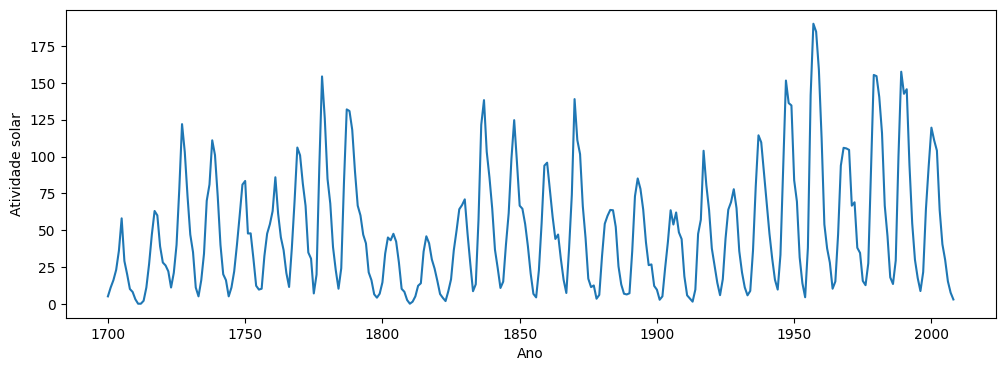

In [66]:
df = sm.datasets.sunspots.load_pandas().data.copy() #dataset de atividade solar
df = df.rename(columns={"YEAR": "Ano", "SUNACTIVITY": "Atividade solar"})
print(df.head())
print(df.shape)

plt.figure(figsize=(12, 4))
plt.plot(df["Ano"], df["Atividade solar"])
plt.xlabel("Ano")
plt.ylabel("Atividade solar")
plt.show()

In [67]:
valores = df["Atividade solar"].to_numpy(dtype=np.float32)
n_total = len(valores) #contar quantos anos existem
fim_treino = int(n_total * 0.70)
fim_validacao = int(n_total * 0.85)
serie_treino = valores[:fim_treino]
serie_validacao = valores[fim_treino:fim_validacao]
serie_teste = valores[fim_validacao:]

print("Treino:", len(serie_treino))
print("Validação:", len(serie_validacao))
print("Teste:", len(serie_teste))

Treino: 216
Validação: 46
Teste: 47


In [68]:
#Normalização sem vazamento de dados
#O passado influencia o futuro, mas o contrário não ocorre
scaler = MinMaxScaler(feature_range=(-1, 1))
treino_scaled = scaler.fit_transform(serie_treino.reshape(-1, 1)).ravel() #aprende o MinMax apenas com os dados de treino
validacao_scaled = scaler.transform(serie_validacao.reshape(-1, 1)).ravel() #aplica o mesmo MinMax para validação
teste_scaled = scaler.transform(serie_teste.reshape(-1, 1)).ravel() #aplica o mesmo MinMax para teste

In [69]:
#Criar janela temporal
LOOKBACK = 2 #define quantos passos/anos serão usados para prever o próximo valor

def criar_janela(serie, lookback):
    X = []
    y = []
    for i in range(lookback, len(serie)):
      X.append(serie[i-lookback:i])
      y.append(serie[i])
    return np.array(X), np.array(y)

X_treino, y_treino = criar_janela(treino_scaled, LOOKBACK)
X_validacao, y_validacao = criar_janela(validacao_scaled, LOOKBACK)
X_teste, y_teste = criar_janela(teste_scaled, LOOKBACK)

print("Treino:", X_treino.shape, y_treino.shape)
print("Validação:", X_validacao.shape, y_validacao.shape)
print("Teste:", X_teste.shape, y_teste.shape)

Treino: (214, 2) (214,)
Validação: (44, 2) (44,)
Teste: (45, 2) (45,)


In [70]:
#Baseline (será um modelo de persistência)
pred_train_persist = X_treino[:, -1] #usar o último valor de cada janela/LOOKBACK de treino como previsão
pred_valid_persist = X_validacao[:, -1] #usar o último valor de cada janela/LOOKBACK de validação como previsão
pred_test_persist = X_teste[:, -1] #usar o último valor de cada janela/LOOKBACK de teste como previsão

#Construindo a RNN

In [71]:
UNITS = 16
LEARNING_RATE = 0.001
BATCH_SIZE = 16
EPOCHS = 100

def construir_modelo(tipo):
  modelo = tf.keras.Sequential()
  modelo.add(tf.keras.layers.Input(shape=(LOOKBACK, 1)))
  modelo.add(tf.keras.layers.LSTM(UNITS, return_sequences=True))
  if tipo == "RNN":
    modelo.add(tf.keras.layers.SimpleRNN(UNITS, activation="tanh"))
  elif tipo == "LSTM":
    modelo.add(tf.keras.layers.LSTM(UNITS, activation = "tanh"))
  elif tipo == "GRU":
    modelo.add(tf.keras.layers.GRU(UNITS, activation = "tanh"))
  modelo.add(tf.keras.layers.Dense(1)) #produz um único valor contínuo como previsão
  modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss="mse", metrics=["mae"])
  return modelo

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience = 10,
    restore_best_weights = True #retornar o melhor peso
)

In [72]:
#Treinar os modelos

modelos = {}
historicos = {}

for nome in ["RNN", "LSTM", "GRU"]:
  modelo = construir_modelo(nome)
  historico = modelo.fit(
      X_treino, y_treino,
      validation_data = (X_validacao, y_validacao),
      batch_size = BATCH_SIZE,
      epochs = EPOCHS,
      callbacks = [early_stop],
      verbose = 2
  )
  modelos[nome] = modelo
  historicos[nome] = historico
  print("Épocas executadas:", len(historico.history["loss"])) #mostrar quantas épocas foram necessárias até o early_stop

Epoch 1/100
14/14 - 20s - 1s/step - loss: 0.2281 - mae: 0.4117 - val_loss: 0.3218 - val_mae: 0.4435
Epoch 2/100
14/14 - 1s - 37ms/step - loss: 0.1388 - mae: 0.3003 - val_loss: 0.3439 - val_mae: 0.4253
Epoch 3/100
14/14 - 1s - 40ms/step - loss: 0.1341 - mae: 0.2729 - val_loss: 0.3276 - val_mae: 0.4182
Epoch 4/100
14/14 - 1s - 60ms/step - loss: 0.1267 - mae: 0.2761 - val_loss: 0.3046 - val_mae: 0.4140
Epoch 5/100
14/14 - 1s - 93ms/step - loss: 0.1224 - mae: 0.2759 - val_loss: 0.2968 - val_mae: 0.4087
Epoch 6/100
14/14 - 0s - 35ms/step - loss: 0.1189 - mae: 0.2696 - val_loss: 0.2893 - val_mae: 0.4042
Epoch 7/100
14/14 - 1s - 42ms/step - loss: 0.1154 - mae: 0.2657 - val_loss: 0.2787 - val_mae: 0.3989
Epoch 8/100
14/14 - 1s - 50ms/step - loss: 0.1116 - mae: 0.2624 - val_loss: 0.2690 - val_mae: 0.3924
Epoch 9/100
14/14 - 1s - 58ms/step - loss: 0.1073 - mae: 0.2573 - val_loss: 0.2586 - val_mae: 0.3843
Epoch 10/100
14/14 - 1s - 48ms/step - loss: 0.1025 - mae: 0.2513 - val_loss: 0.2466 - val_ma

In [73]:
#Conferir o desempenho
def inverter_escala(vetor):
  vetor = np.asarray(vetor).reshape(-1, 1)
  return scaler.inverse_transform(vetor).ravel() #Desfaz a normalização

def calcular_metricas(y_real_scaled, y_pred_scaled):
  y_real = inverter_escala(y_real_scaled)
  y_pred = inverter_escala(y_pred_scaled)
  mae = mean_absolute_error(y_real, y_pred)
  mse = mean_squared_error(y_real, y_pred)
  rmse = np.sqrt(mse)
  r2 = r2_score(y_real, y_pred)
  return mae, mse, rmse, r2

In [74]:
#Comparar treino, validação e teste

resultados = []
splits = {
    "Treino": (X_treino, y_treino, pred_train_persist),
    "Validação": (X_validacao, y_validacao, pred_valid_persist),
    "Teste": (X_teste, y_teste, pred_test_persist)
}

for split_nome, (X_split, y_split, baseline_pred) in splits.items():
  mae, mse, rmse, r2 = calcular_metricas(y_split, baseline_pred)
  resultados.append([split_nome, "Persistência", mae, rmse, r2])
  for nome, modelo in modelos.items():
    mae, mse, rmse, r2 = calcular_metricas(y_split, modelo.predict(X_split))
    resultados.append([split_nome, nome, mae, rmse, r2])

resultados_df = pd.DataFrame(resultados, columns=["Split", "Modelo", "MAE", "RMSE", "R²"])
print(resultados_df.round(4))

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 191ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 213ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
        Split        Modelo      MAE     RMSE      R²
0      Treino  Persistência  16.0131  20.7001  0.6334
1      Treino           RNN   9.7850  12.9259  0.8571
2      Treino          LSTM  38.4492  43.7845 -0.6402
3      Treino           GRU  37.8998  43.4665 -0.6165
4   Validação  Persistência  24.2500  31.3488  0.6129
5   Validação           RNN  14.1122  20.6069  0.8328
6   Validação          LSTM  41.5051  49.5579  0.0327
7   Validação           GRU  41.8545  50.8094 -0.0168
8       Teste  Persistência  22.7378  29.5996  0.6142
9       Teste           RNN  16.0194  19.3569  0.8350
10      Teste          LSTM  41.9472  46.7830  0.0363
11     

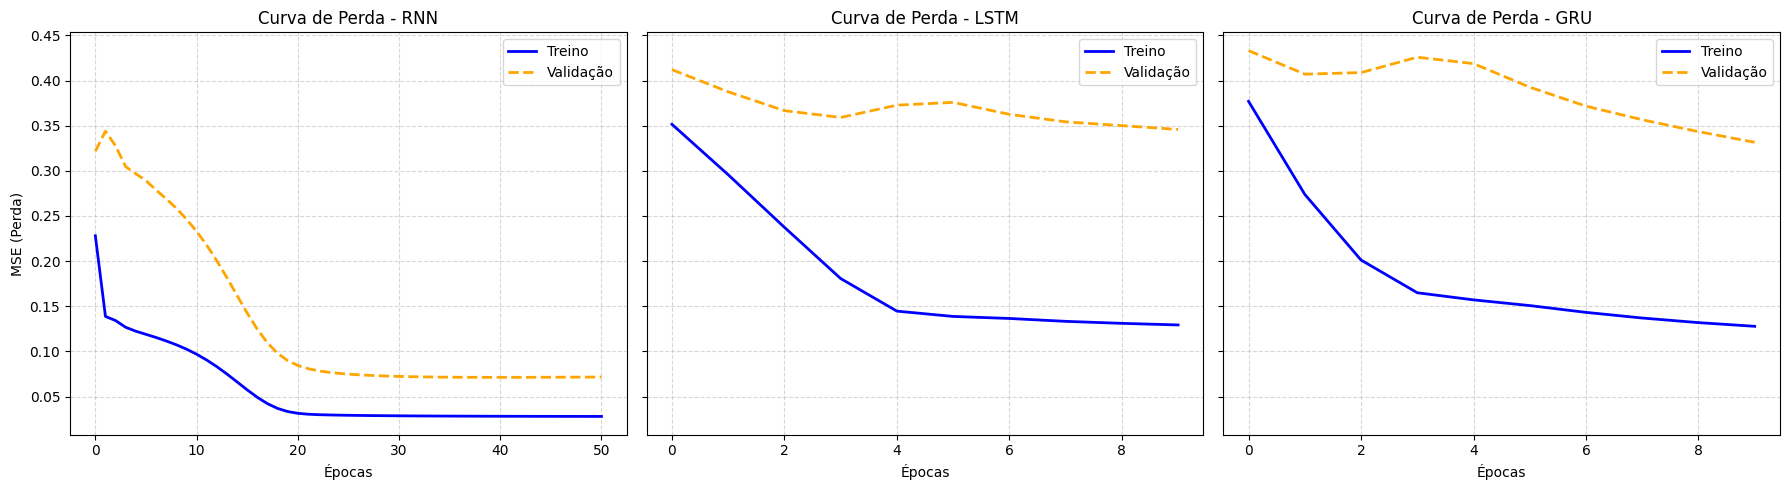

In [88]:
# Curvas de desempenho separadas por modelo para evitar confusão de sequências
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for i, (nome, historico) in enumerate(historicos.items()):
    ax = axes[i]
    ax.plot(historico.history["loss"], label="Treino", color="blue", linewidth=2)
    ax.plot(historico.history["val_loss"], label="Validação", color="orange", linestyle="--", linewidth=2)
    ax.set_title(f"Curva de Perda - {nome}")
    ax.set_xlabel("Épocas")
    if i == 0:
        ax.set_ylabel("MSE (Perda)")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


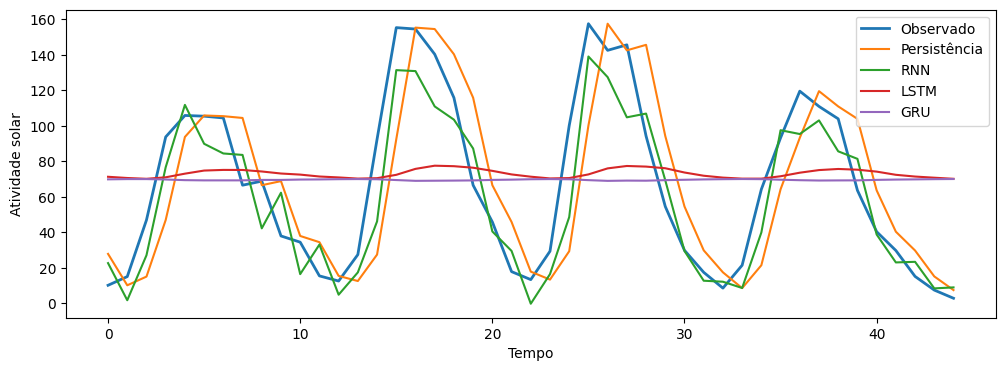

In [76]:
#Observado vs Previsto

y_teste_original = inverter_escala(y_teste)
plt.figure(figsize=(12, 4))
plt.plot(y_teste_original, label="Observado", linewidth=2)
plt.plot(inverter_escala(pred_test_persist), label="Persistência")
for nome, modelo in modelos.items():
  pred = modelo.predict(X_teste).ravel()
  plt.plot(inverter_escala(modelo.predict(X_teste)), label=f"{nome}")
plt.xlabel("Tempo")
plt.ylabel("Atividade solar")
plt.legend()
plt.show()

# **Transformers**

In [77]:
%pip install -q numpy pandas matplotlib scikit-learn tensorflow	transformers sentence-transformers torch

In [78]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import tensorflow as tf
import torch
import re
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer #Carrega o tokenizador do DistilBERT
from transformers import AutoModel #Carrega o transformer do DistilBERT

In [79]:
VOCAB_SIZE = 10000 #Manter apenas as 10 mil palavras mais frequentes do dataset
N_SAMPLES = 3000 #Limita o número de amostra/texto

(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.imdb.load_data(num_words=VOCAB_SIZE)
x_all = np.concatenate([x_train_raw, x_test_raw])
y_all = np.concatenate([y_train_raw, y_test_raw])

word_index = tf.keras.datasets.imdb.get_word_index() #Carregando o dicionário de palavras
reverse_index = {indice + 3: palavra for palavra, indice in word_index.items()}
reverse_index[0] = "<PAD>" #Definindo o token de preenchimento
reverse_index[1] = "<START>" #Token de início
reverse_index[2] = "<UNK>" #Token de palavra desconhecida
reverse_index[3] = "<UNUSED>" #Token de palavra reservada

def decodificar_review(sequencia): #Converte a sequência de ID em texto novamente
  palavras = [reverse_index.get(int(i), '<UNK>') for i in sequencia] # Traduz cada ID para a palavra correspondente
  texto = ' '.join(palavras) # juntas todas as palavras como uma única/string
  texto = texto.replace('<START>', '') #remover o marcador de início
  texto = texto.replace('<PAD>', '') #remover o token de preenchimento
  texto = re.sub(r'\s+', ' ', texto) #remover espaços em branco adicionais
  return texto

rng = np.random.default_rng(SEED)
indices = rng.choice(len(x_all), size=N_SAMPLES, replace=False) #Seleciona uma amostra sem repetição
textos = np.array([decodificar_review(x_all[i]) for i in indices], dtype=object)
rotulos = y_all[indices].astype(int) #seleciona os rotulos correspondentes: 0 negativo, 1 positivo

print(textos[0][:500]) #Mostrar parte de um texto reconstruído
print('Rótulo:', rotulos[0]) #Mostra a classe do texto

 it's a <UNK> <UNK> cyborg movie with a love story <UNK> it's not as bad as it sounds the action when it is there is decent and jack palance <UNK> <UNK> and angelina jolie are always <UNK> it's the fact that this is a sequel to the terrible jean claude van damme film or is that the <UNK> to the masters of the universe trilogy i'm still confused about that either way there was really no need for this movie what was there a need for angelina jolie she may play an assassin robot that can explodes m
Rótulo: 0


In [80]:
X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    textos,
    rotulos,
    test_size=0.3, #30% p/ validação + teste
    random_state=SEED,
    stratify=rotulos
)

X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text,
    y_temp,
    test_size=0.5, #50% p/ teste
    random_state=SEED,
    stratify=y_temp
)

print("Treino:", len(X_train_text))
print("Validação:", len(X_val_text))
print("Teste:", len(X_test_text))

Treino: 2100
Validação: 450
Teste: 450


In [81]:
#função comum para avaliação
resultados = []

def avaliar_classificador(nome, conjunto, y_real, probabilidades):
  probabilidades = np.asarray(probabilidades).ravel()
  previsoes = (probabilidades >= 0.5).astype(int)
  acc = accuracy_score(y_real, previsoes)
  f1 = f1_score(y_real, previsoes)
  auc = roc_auc_score(y_real, probabilidades)
  resultados.append([nome, conjunto, acc, f1, auc]) #guarda os valores das métricas calculadas

In [82]:
MAX_TOKENS = 10000 #tamanho máximo do vocabulário
SEQ_LEN = 200 #Número máximo de token por avaliação
EMBED_DIM = 64 #dimensão do embedding aprendido por cada token
LSTM_UNIT = 32

vectorizer = tf.keras.layers.TextVectorization( #converte o texto em IDs de tokens
    max_tokens=MAX_TOKENS,
    output_mode='int', #retorna inteiros
    output_sequence_length=SEQ_LEN,
)

vectorizer.adapt(X_train_text) #aprende o vocabulário somente a partir dos dados de treino

lstm_model = tf.keras.Sequential()
lstm_model.add(tf.keras.layers.Input(shape=(), dtype=tf.string))
lstm_model.add(vectorizer)
lstm_model.add(tf.keras.layers.Embedding(MAX_TOKENS, EMBED_DIM, mask_zero=True))
lstm_model.add(tf.keras.layers.LSTM(LSTM_UNIT))
lstm_model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_lstm = lstm_model.fit(
    X_train_text, y_train,
    validation_data=(X_val_text, y_val),
    batch_size=32,
    epochs=100,
    callbacks=[early_stop],
    verbose=2
)

avaliar_classificador('LSTM', 'Treino', y_train, lstm_model.predict(X_train_text))
avaliar_classificador('LSTM', 'Validação', y_val, lstm_model.predict(X_val_text))
avaliar_classificador('LSTM', 'Teste', y_test, lstm_model.predict(X_test_text))

Epoch 1/100
66/66 - 40s - 608ms/step - accuracy: 0.5310 - loss: 0.6878 - val_accuracy: 0.6533 - val_loss: 0.6646
Epoch 2/100
66/66 - 17s - 256ms/step - accuracy: 0.7762 - loss: 0.5041 - val_accuracy: 0.7867 - val_loss: 0.5018
Epoch 3/100
66/66 - 19s - 293ms/step - accuracy: 0.9143 - loss: 0.2211 - val_accuracy: 0.8089 - val_loss: 0.5249
Epoch 4/100
66/66 - 13s - 192ms/step - accuracy: 0.9690 - loss: 0.1083 - val_accuracy: 0.8178 - val_loss: 0.5269
Epoch 5/100
66/66 - 8s - 120ms/step - accuracy: 0.9848 - loss: 0.0644 - val_accuracy: 0.7133 - val_loss: 0.6311
Epoch 6/100
66/66 - 7s - 101ms/step - accuracy: 0.9767 - loss: 0.0759 - val_accuracy: 0.7000 - val_loss: 0.7680
Epoch 7/100
66/66 - 4s - 65ms/step - accuracy: 0.9757 - loss: 0.0754 - val_accuracy: 0.6644 - val_loss: 1.0960
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step


In [83]:
#SBERT
sbert = SentenceTransformer('all-MiniLM-L6-v2')

# Usando as variáveis de texto decodificadas corretas para gerar os embeddings
emb_train_sbert = sbert.encode(X_train_text, batch_size=32, show_progress_bar=True)
emb_val_sbert = sbert.encode(X_val_text, batch_size=32, show_progress_bar=True)
emb_test_sbert = sbert.encode(X_test_text, batch_size=32, show_progress_bar=True)

clf_sbert = LogisticRegression(max_iter=1000, random_state=SEED)
clf_sbert.fit(emb_train_sbert, y_train)

# Avaliação com as métricas usando os rótulos correspondentes
avaliar_classificador('SBERT', 'Treino', y_train, clf_sbert.predict_proba(emb_train_sbert)[:, 1])
avaliar_classificador('SBERT', 'Validação', y_val, clf_sbert.predict_proba(emb_val_sbert)[:, 1])
avaliar_classificador('SBERT', 'Teste', y_test, clf_sbert.predict_proba(emb_test_sbert)[:, 1])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/66 [00:00<?, ?it/s]

Batches:   0%|          | 0/15 [00:00<?, ?it/s]

Batches:   0%|          | 0/15 [00:00<?, ?it/s]

In [62]:
#Transformer
MODEL_NAME = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
transformer = AutoModel.from_pretrained(MODEL_NAME) # Corrigido de model para transformer
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
transformer = transformer.to(device)
transformer.eval()

def mean_pooling(last_hidden_state, attention_mask):  # Resume embeddings de tokens em um único vetor por texto.
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()  # Expande a máscara para a mesma dimensão dos embeddings.
    soma = torch.sum(last_hidden_state * mask, dim=1)  # Soma somente tokens válidos.
    divisor = torch.clamp(mask.sum(dim=1), min=1e-9)  # Conta os tokens válidos e evita divisão por zero.
    return soma / divisor  # Calcula a média dos embeddings contextuais.

def gerar_embeddings_transformer(textos, batch_size=16, max_length=256):  # Gera embeddings em lotes para economizar memória.
    todos_embeddings = []  # Cria a lista que receberá os vetores de cada lote.
    for inicio in range(0, len(textos), batch_size):  # Percorre os textos em pequenos lotes.
        lote = textos[inicio:inicio + batch_size].tolist()  # Seleciona o lote atual.
        tokens = tokenizer(  # Tokeniza o lote.
            lote,  # Fornece os textos.
            padding=True,  # Completa sequências menores.
            truncation=True,  # Corta sequências muito longas.
            max_length=max_length,  # Limita cada texto a 256 tokens.
            return_tensors='pt',  # Solicita tensores PyTorch.
        )  # Finaliza a tokenização.
        tokens = {chave: valor.to(device) for chave, valor in tokens.items()}  # Move os tensores para CPU ou GPU.
        with torch.no_grad():  # Desativa o cálculo de gradientes porque não treinaremos o Transformer.
            saida = transformer(**tokens)  # Executa o self-attention e gera embeddings contextuais por token.
            pooled = mean_pooling(saida.last_hidden_state, tokens['attention_mask'])  # Resume cada texto em um único vetor contextual.
        todos_embeddings.append(pooled.cpu().numpy())  # Move os vetores para CPU e guarda o lote.
    return np.vstack(todos_embeddings)  # Junta todos os lotes em uma única matriz.

# Corrigido chamadas de funções usando o nome correto no plural
emb_train_bert = gerar_embeddings_transformer(X_train_text)
emb_val_bert = gerar_embeddings_transformer(X_val_text)
emb_test_bert = gerar_embeddings_transformer(X_test_text)

clf_bert = LogisticRegression(max_iter=1000, random_state=SEED)
clf_bert.fit(emb_train_bert, y_train)

avaliar_classificador('Transformer', 'Treino', y_train, clf_bert.predict_proba(emb_train_bert)[:, 1])
avaliar_classificador('Transformer', 'Validação', y_val, clf_bert.predict_proba(emb_val_bert)[:, 1])
avaliar_classificador('Transformer', 'Teste', y_test, clf_bert.predict_proba(emb_test_bert)[:, 1])

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [84]:
#Tabela final de resultados
resultados_df = pd.DataFrame(resultados, columns=['Modelo', 'Conjunto', 'Acurácia', 'F1', 'AUC'])
print(resultados_df.round(4))

  Modelo   Conjunto  Acurácia      F1     AUC
0   LSTM     Treino    0.9086  0.9153  0.9772
1   LSTM  Validação    0.7867  0.8147  0.8629
2   LSTM      Teste    0.7511  0.7829  0.8370
3  SBERT     Treino    0.8533  0.8594  0.9251
4  SBERT  Validação    0.8111  0.8195  0.9025
5  SBERT      Teste    0.7844  0.7932  0.8775


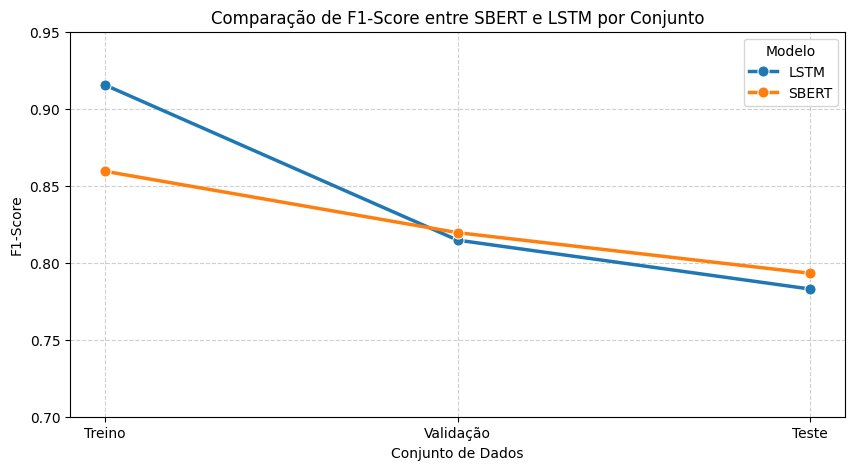

In [87]:
#Comparação visual (Gráfico de linhas para Treino, Validação e Teste)
import seaborn as sns

# Garantir que a ordem dos conjuntos faça sentido no eixo X
ordenacao_conjuntos = {'Treino': 0, 'Validação': 1, 'Teste': 2}

# Filtrar e preparar os dados para os modelos desejados (SBERT e LSTM)
plot_df = resultados_df[resultados_df['Modelo'].isin(['SBERT', 'LSTM'])].copy()
plot_df['Ordem'] = plot_df['Conjunto'].map(ordenacao_conjuntos)
plot_df = plot_df.sort_values(by=['Modelo', 'Ordem'])

plt.figure(figsize=(10, 5))
sns.lineplot(data=plot_df, x='Conjunto', y='F1', hue='Modelo', marker='o', linewidth=2.5, markersize=8)
plt.title('Comparação de F1-Score entre SBERT e LSTM por Conjunto')
plt.xlabel('Conjunto de Dados')
plt.ylabel('F1-Score')
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim(0.7, 0.95) # Define um limite para melhor visualização das diferenças
plt.show()

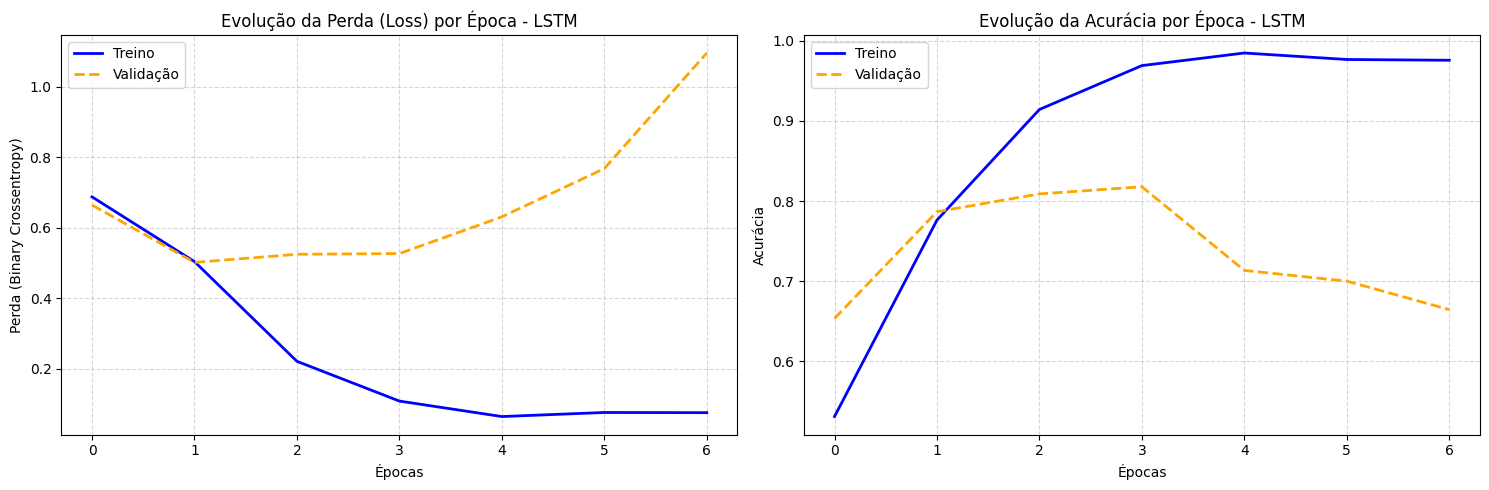

In [89]:
# Gráfico de evolução do treino do LSTM por épocas (Classificação IMDB)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Perda (Loss)
ax1.plot(history_lstm.history['loss'], label='Treino', color='blue', linewidth=2)
ax1.plot(history_lstm.history['val_loss'], label='Validação', color='orange', linestyle='--', linewidth=2)
ax1.set_title('Evolução da Perda (Loss) por Época - LSTM')
ax1.set_xlabel('Épocas')
ax1.set_ylabel('Perda (Binary Crossentropy)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Acurácia (Accuracy)
ax2.plot(history_lstm.history['accuracy'], label='Treino', color='blue', linewidth=2)
ax2.plot(history_lstm.history['val_accuracy'], label='Validação', color='orange', linestyle='--', linewidth=2)
ax2.set_title('Evolução da Acurácia por Época - LSTM')
ax2.set_xlabel('Épocas')
ax2.set_ylabel('Acurácia')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()